# `Beam` — full design walkthrough

This notebook exercises the **entire public API** of the `Beam` element of
`design/` (ACI 318‑25), following one **canonical 12‑step flow**. Every element
— `Beam`, `Column`, `Wall`, `BeamColumnJoint` — shares this same skeleton, so the
*architecture* is identical and only the **physics** changes.

> **Rational structure.** The element is an immutable object. You *create* it,
> *run* it to cache capacities, *review* a given reinforcement against demands,
> let it *design* a proposal, and *adopt* that proposal by producing a **new**
> element. Reporting and plotting sit on top. The shared base class
> `design.common.element_base.ElementBase` provides the parts that are identical
> across elements (`apply`, `set_units`); the runtime `Element` protocol
> (`design.common.contracts`) is the canonical `isinstance` test.

### The 12‑step contract

| Step | Call | Purpose |
|------|------|---------|
| 1 | `Concrete(...)`, `Steel(...)` | materials (MPa) |
| 2 | `Beam.rectangular(...)` | **create** — every input argument shown |
| 3 | `el.run()` | lazy‑compute + cache capacity (returns `self`) |
| 4 | `el.capacity()` | capacity of the **as‑built** reinforcement |
| 5 | `el.demands(...)` | build the load set (display units → internal) |
| 6 | `el.check(demands)` | **review** the current rebar → PASS/FAIL |
| 7 | `el.design(demands)` | automatic **proposal** (multiple modes) |
| 8 | `results.envelope.<field>` | read the result **explicitly** (no magic) |
| 9 | `el.evolve(p)` / `el.apply(p)` | adopt → **new immutable** element |
| 10 | `report()` / `summary()` / `set_units()` / `print_final()` | reporting |
| 11 | `el.plot.*` | plotting |
| 12 | `el.run_optimize(demands)` | sweep detailing alternatives |

**Physics of this element.** A beam is a **flexure + shear** member (ACI §9, SMF detailing §18.6). Design is closed‑form: `phi*Mn+`, `phi*Mn-`, `phi*Vn`, and the probable moment `Mpr` (§18.6.5.1) that drives the capacity‑design shear `Ve`.

**By‑design exceptions.** A beam exposes a P‑M interaction curve **for inspection only** (`beam.pm`); ordinary design never uses it. Demands are given at **three stations** (face‑i / mid / face‑j).

> **Internal units (non‑negotiable):** stress = MPa, length = mm, force = kN,
> moment = kN·m, area = mm². The `units=` argument only controls *presentation*.


## Step 1 — Materials

Concrete and steel are immutable value objects in **MPa**.

In [1]:
# Notebook setup: inline figures, repo on sys.path, silence the metre→mm warning
%matplotlib inline
import sys, pathlib, warnings
warnings.simplefilter("ignore", DeprecationWarning)

# Make `design` importable whether or not the repo is pip-installed:
_root = pathlib.Path.cwd().resolve()
while _root != _root.parent and not (_root / "design" / "__init__.py").is_file():
    _root = _root.parent
if (_root / "design").is_dir() and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from design.common.materials import Concrete, Steel
from design.beams.beam import Beam

concrete = Concrete(fc=28.0)   # f'c = 28 MPa
steel    = Steel(fy=420.0)     # fy = 420 MPa (Grade 60)
concrete, steel

(Concrete(fc=28.0, unit_weight=24.0, lightweight=False, sand_lightweight=False),
 Steel(fy=420.0, Es=200000.0, fu=None, grade=60, density=7850.0))

## Step 2 — Create the beam

`Beam.rectangular(...)` is the one‑shot factory: it builds the section, the two rebar layers and the hoop cage in a single call. Every argument below is an **input method** of the beam.

In [2]:
beam = Beam.rectangular(
    bw=300, h=500, cover=40,        # geometry (mm)
    concrete=concrete, steel=steel, # materials
    n_top=4, db_top=22,             # top longitudinal layer
    n_bot=4, db_bot=22,             # bottom longitudinal layer
    db_stirrup=10, n_legs=2,        # transverse hoop
    s_stirrup=150,                  # hoop spacing (mm)
    ln=5000.0,                      # clear span (mm)
    Vg=60.0,                        # gravity shear (kN)
    seismic=True,                   # SMF detailing (ACI §18.6)
    label="B-301",
)
beam

Beam(label='B-301', section=300x500 mm, fc=28.00 N/mm^2, units=N_mm_C)

## Step 3 — `run()`

Lazily computes and caches the capacities, then returns `self` so calls can be chained. Nothing is mutated except the internal cache.

In [3]:
beam.run()
print(f"phi_Mn_pos = {beam.phi_Mn_pos:.1f} kN·m")
print(f"phi_Mn_neg = {beam.phi_Mn_neg:.1f} kN·m")
print(f"phi_Vn     = {beam.phi_Vn:.1f} kN")

phi_Mn_pos = 217.3 kN·m
phi_Mn_neg = 217.3 kN·m
phi_Vn     = 233.7 kN


## Step 4 — `capacity()`

A snapshot of the **as‑built** reinforcement: probable moments, reinforcement ratios, and the tension‑controlled flag. The inspection‑only P‑M curve is reachable via `beam.phi_Mn.at(...)`.

In [4]:
cap = beam.capacity()
print(f"Mpr_pos = {cap.Mpr_pos:.1f} kN·m   Mpr_neg = {cap.Mpr_neg:.1f} kN·m")
print(f"rho = {cap.rho:.4f}  (min {cap.rho_min:.4f}, max {cap.rho_max:.4f})")
print(f"tension_controlled = {cap.tension_controlled}")
print(f"[inspection] phi_Mn at Nu=0 (+) = "
      f"{beam.phi_Mn.at(Nu=0, direction='pos'):.1f} kN·m")

Mpr_pos = 305.8 kN·m   Mpr_neg = 305.8 kN·m
rho = 0.0115  (min 0.0033, max 0.0142)
tension_controlled = True
[inspection] phi_Mn at Nu=0 (+) = 229.1 kN·m


## Step 5 — `demands(...)`

The builder reads values in **display units** and converts them to the internal kN / kN·m. A beam carries demands at three stations (i / mid / j).

In [5]:
demands = beam.demands(
    Mu_pos_i=80, Mu_neg_i=160, Vu_i=200,
    Mu_pos_mid=200, Mu_neg_mid=40, Vu_mid=80,
    Mu_pos_j=80, Mu_neg_j=160, Vu_j=200,
)
print(f"Vu_max = {demands.Vu_max:.1f} kN")

Vu_max = 0.2 kN


## Step 6 — `check(demands)`

Reviews the **current** reinforcement against the demands and returns a `BeamCheck` with the per‑station ratios, the rho / tension‑controlled / SMF‑continuity flags and an overall `passed`.

In [6]:
chk = beam.check(demands)
print(f"passed = {chk.passed}")
beam.print_checks(demands)

passed = True
=== B-301 -- ACI 318-25 Checks ===  (units: N_mm_C)
Sec.9.6.1.2 / 22.2  Cuantia (range 0.5*rho_b):
  rho  (bot) = 0.0115    [0.0033 .. 0.0142]   OK
  rho' (top) = 0.0115    [0.0033 .. 0.0142]   OK
  rho_balanced = 0.0283    (ACI Sec.18.6.3.1 SMF cap = 0.0250)
Sec.21.2.2          Tension-controlled                          : OK
Sec.18.6.3.2        >=2 bars continuous (top, bot)            : requires layout check at apply()
Sec.18.6.3.3        phi_Mn+ >= 0.5 phi_Mn-                    : 1.00   OK
Sec.18.6.3.4        phi_Mn anywhere >= 0.25 max               : 1.00   OK
Demand ratios (per station):
  M (i)  +/-: 0.00 / 0.00
  M (mid)+/-: 0.00 / 0.00
  M (j)  +/-: 0.00 / 0.00
  V (i/mid/j): 0.00 / 0.00 / 0.00
  Overall passed = True
---
Steel quantities (kg/m^3 of concrete):
  rho_long  = 159.15
  rho_trans = 35.07
  rho_total = 194.22


## Step 7 — `design(demands)`

Produces a `BeamDesignResults` holding four proposals: **minimum** (ACI floors), **demand** (from the loads), **capacity** (`Ve` from `Mpr`, with `Vc = 0` in `lo` per §18.6.5.2) and the pointwise **envelope**. `design()` never mutates `self`.

In [7]:
results = beam.design(demands)
beam.print_design(results, demands=demands)

=== B-301 Design Results ===  (units: N_mm_C)

--- PROVIDED ---
  Top         : 4phi22    (As = 1521 mm^2)
  Bottom      : 4phi22    (As = 1521 mm^2)
  Stirrups    : phi10 x 2 legs @ 150 mm
  phi*Mn (+/-): 217259529.2 N.mm / 217259529.2 N.mm
  phi*Vn      : 233665.3 N
  Mpr (+/-)   : 305819075.2 N.mm / 305819075.2 N.mm   -> Ve_capacity = 182327.6 N
  rho / rho'  : 0.0115 / 0.0115    range [0.0033 .. 0.0142]    OK
  Demand check: ratio M = 0.00   ratio V (i/m/j) = 0.00 / 0.00 / 0.00   passed = True

--- MINIMUM ---
  Top         : 4phi12    (As = 452 mm^2)
  Bottom      : 4phi12    (As = 452 mm^2)
  Stirrups    : phi10 x 2 legs @ 96 mm   (middle s = 220 mm, lo = 1000 mm)
  Mpr (+/-)   : 305819075.2 N.mm / 305819075.2 N.mm   -> Ve_capacity = 182327.6 N
  phi*Vn      : 315121.9 N   Ve/phiVn = 0.58
  steel (kg/m^3): rho_long = 47.4    rho_trans = 54.8    rho_total = 102.2

--- DEMAND ---
  Top         : 4phi12    (As = 452 mm^2)
  Bottom      : 4phi12    (As = 452 mm^2)
  Stirrups    : phi

## Step 8 — Read the result **explicitly**

There is **no magic attribute proxy**: you always name the mode you want (`results.envelope`, `results.capacity`, …). A typo raises `AttributeError` instead of silently returning the wrong value.

In [8]:
env = results.envelope            # pick the mode explicitly
print(f"mode            = {env.mode}")
print(f"top continuous  = {env.n_top} φ{env.db_top:.0f}")
print(f"bot continuous  = {env.n_bot} φ{env.db_bot:.0f}")
print(f"stirrups        = {env.n_legs} φ{env.db_stirrup:.0f} @ "
      f"{env.spacing_confined:.0f}/{env.spacing_middle:.0f} mm")

mode            = envelope
top continuous  = 4 φ12
bot continuous  = 4 φ12
stirrups        = 2 φ10 @ 96/220 mm


## Step 9 — `evolve()` / `apply()`

Adopting a proposal returns a **new, immutable** beam (the original is untouched). `apply` is an alias of `evolve`, provided uniformly by `ElementBase`.

In [9]:
beam2 = beam.evolve(env)
assert beam2 is not beam              # original untouched
_ = beam.apply(env)                   # apply == evolve
print(f"original phi_Vn = {beam.phi_Vn:.1f} kN")
print(f"evolved  phi_Vn = {beam2.run().phi_Vn:.1f} kN")

original phi_Vn = 233.7 kN
evolved  phi_Vn = 318.7 kN


## Step 10 — Reporting

`report()` returns a structured dict; `summary()` prints a human block; `set_units()` swaps the presentation unit system; `print_final()` is the consolidated design sheet.

In [10]:
print("report keys =", sorted(beam2.report()))
beam2.set_units("kN_m_C")             # code 6 = kN, m, °C
beam2.summary()
beam2.print_final(env, demands=demands)

report keys = ['capacity', 'label', 'materials', 'params', 'rebar', 'section', 'units']
=== B-301 ===  (units: kN_m_C)
Section   : 0.300x0.500 m
Materials : fc = 28000.00 kN/m^2, fy = 420000.00 kN/m^2
Rebar     : 8 bars, As_tot = 905 mm^2
            rho  = 0.0034  (bottom)
            rho' = 0.0034  (top)
            range [rho_min = 0.0033 .. rho_max = 0.0142]
            rho_b = 0.0283  (rho_max = 0.5*rho_b)
phi*Mn+   : 66.3 kN.m
phi*Mn-   : 66.3 kN.m
phi*Vn    : 318.7 kN
Mpr+      : 101.5 kN.m
Mpr-      : 101.5 kN.m
TC        : True
Stirrups  : phi10 x 2 legs @ 0.096 m
Steel quantities (kg/m^3 of concrete):
  rho_long  = 47.35
  rho_trans = 54.80
  rho_total = 102.15

  BEAM -- FINAL DESIGN   |   B-301   |   units: kN_m_C
  Section          : 0.300 x 0.500 m   cover = 0.040 m
  Materials        : fc' = 28000.00 kN/m^2    fy = 420000.00 kN/m^2
  Span (clear)     : ln = 5.000 m
----------------------------------------------------------------------------
  Longitudinal:
    Top       

## Step 11 — Plotting

`beam.plot.*` returns matplotlib figures. The 2×2 dashboard summarises section, capacities and demand; `plot.pm()` draws the inspection‑only P‑M curve.

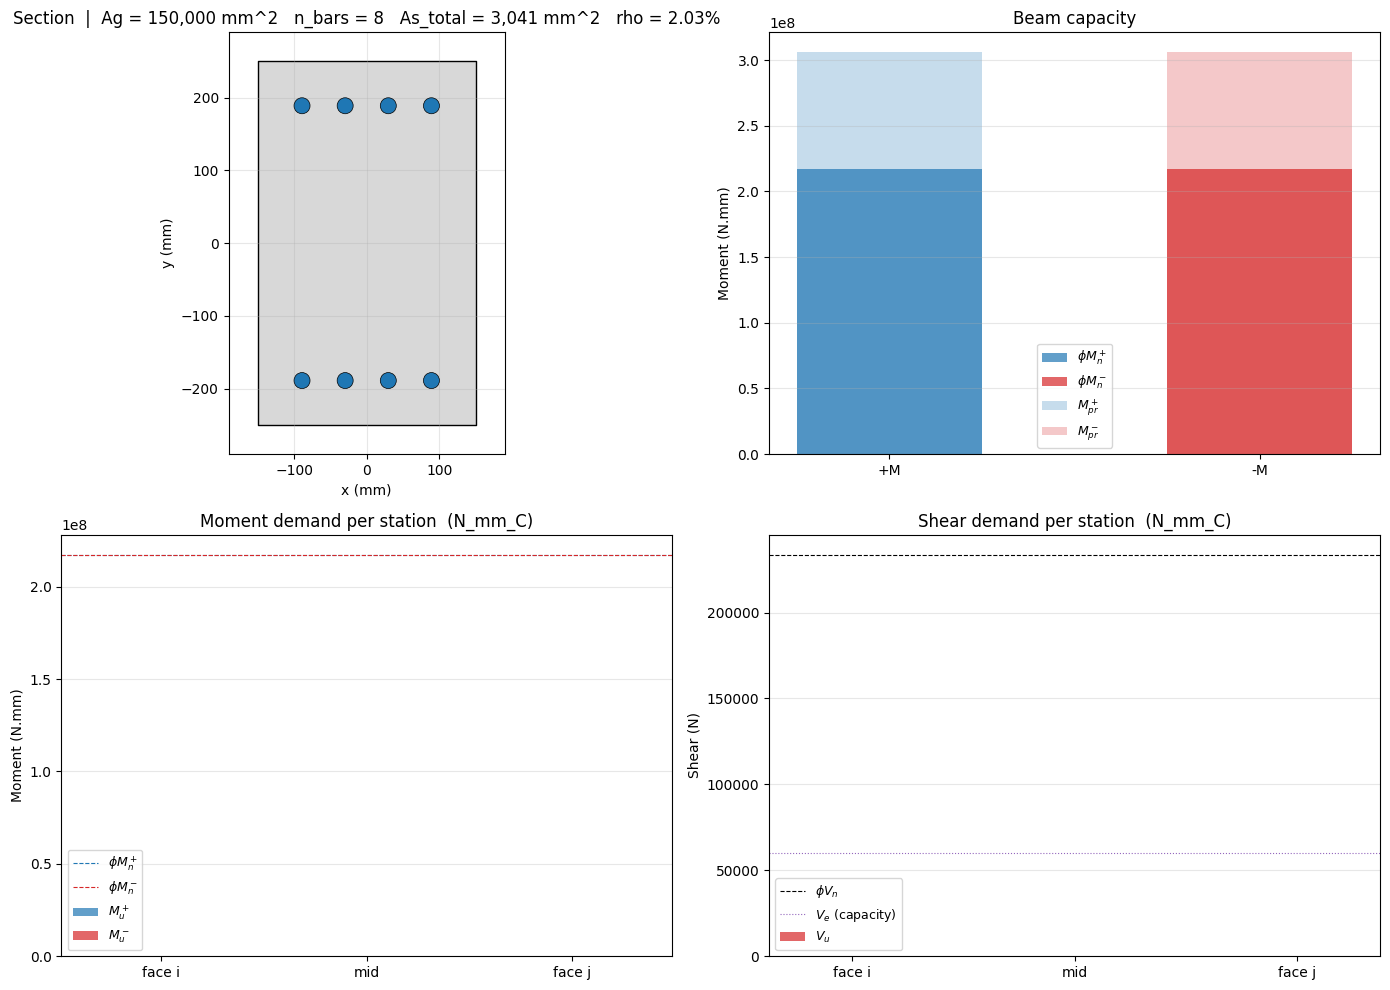

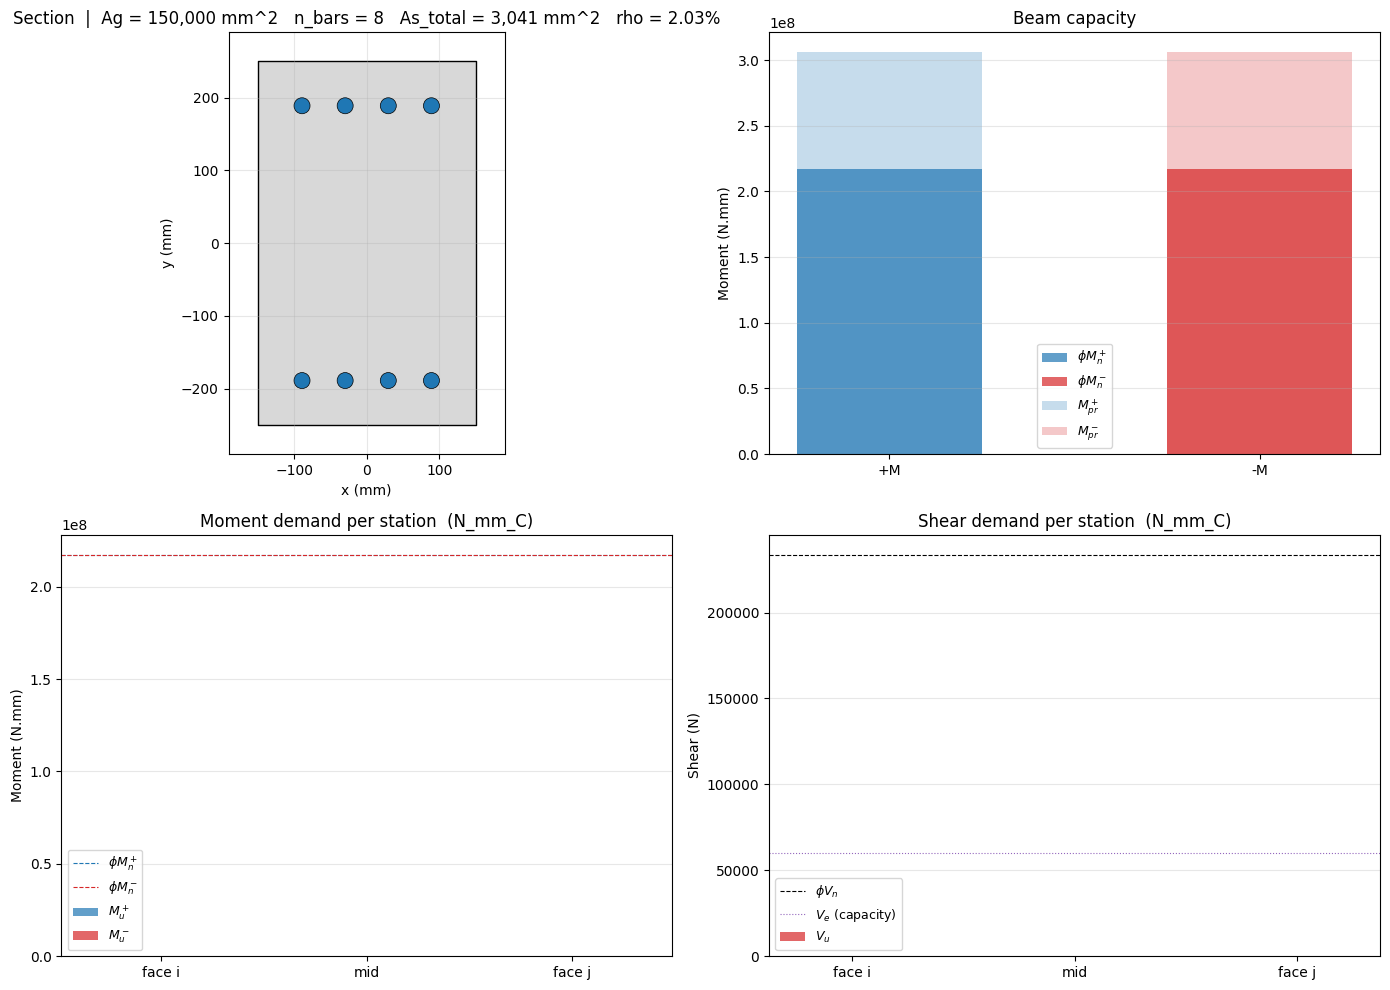

In [11]:
fig = beam.plot.dashboard(demands=demands)
fig

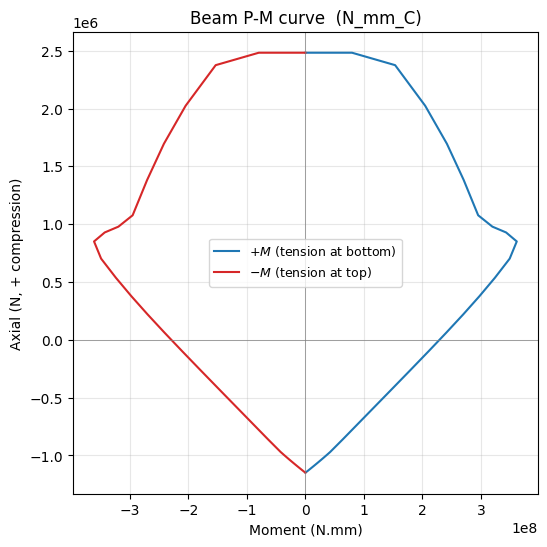

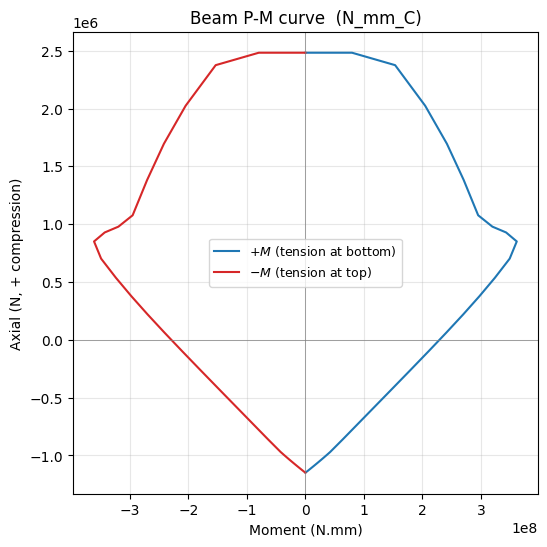

In [12]:
ax = beam.plot.pm(direction="both")
ax.figure

## Step 12 — `run_optimize(demands)`

Sweeps bar/leg combinations and ranks them by steel weight (kg/m³). Method form for parity with `Column`/`Wall`.

In [13]:
alts = beam.run_optimize(demands)
print(f"{len(alts)} alternatives; best rho_total = "
      f"{alts[0].rho_total:.1f} kg/m³")

442 alternatives; best rho_total = 102.2 kg/m³


---
### Architecture recap

Everything above — `run`, `capacity`, `check`, `design`, `evolve`/`apply`, `summary`, `report`, `set_units`, `plot`, `run_optimize` — is the **same shape** for every element. Only the dataclasses (`BeamDemands`…) and the physics differ. See the column / wall / joint notebooks to watch the identical skeleton wrap different mechanics.